# Caso 03 — NidoHogar, portal inmobiliario: del clic al contrato
## Día 5 — Que se Entienda y Cambie Algo: Los 4 Gráficos Ejecutivos y el One-Pager

**Audiencia del Comité de Dirección:**
* **Álvaro Nadal (CEO):** Quiere saber dónde invertir para hacer crecer contratos y comisiones reales.
* **Gonzalo Prieto (Director Comercial):** Defiende el lanzamiento de *«Destacado Premium»* apoyándose en que el destacado duplica visitas y contactos.
* **Cristina Márquez (PM del Marketplace):** Sospecha que el embudo pierde agua entre el contacto y la firma.
* **Irene Salas (Lead de Datos):** Exige rigor metodológico, limpieza auditable y control de variables de confusión.

**Objetivo del Día 5:**
Generar y guardar en `reports/` los **4 gráficos ejecutivos** que estructuran la historia completa (y mantener actualizadas las copias de raíz), seguidos de la tabla maestra y la recomendación accionable para el Comité:
1. [`reports/01_embudo_destacado_vs_normal.png`](reports/01_embudo_destacado_vs_normal.png) — *Primero la razón, luego la grieta: Visitas y contactos por anuncio vs. Tasa de conversión a contrato y Comisión total.*
2. [`reports/02_velocidad_respuesta_conversion.png`](reports/02_velocidad_respuesta_conversion.png) — *La palanca reina: Conversión a contrato y cuota de comisiones según tramo de tiempo de respuesta (`<2h` `14,00 %` vs `sin_respuesta` `0,50 %`).*
3. [`reports/03_saturacion_agencias_destacado.png`](reports/03_saturacion_agencias_destacado.png) — *El mecanismo causal: Reparto de contactos por tramo de respuesta (`50,0 %` ignorados en destacado vs `33,0 %` en normal).*
4. [`reports/04_control_confusion_tramos_respuesta.png`](reports/04_control_confusion_tramos_respuesta.png) — *El blindaje científico: Dentro del mismo tramo de respuesta (`<2h`), destacado (`13,99 %`) y normal (`14,01 %`) convierten exactamente igual.*

In [1]:
%matplotlib inline
import os
from pathlib import Path
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

REPORTS_DIR = Path('reports')
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cbd5e1'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 130

con = duckdb.connect()
for tabla in ['anuncios', 'visitas', 'contactos', 'contratos', 'agencias', 'zonas', 'productos_visibilidad']:
    con.execute(f"CREATE OR REPLACE VIEW v_{tabla} AS SELECT * FROM read_csv_auto('data/clean/{tabla}_clean.csv')")

# Tabla Maestra por Tipo de Anuncio
q_maestra_tipo = """
WITH v_por_a AS (
    SELECT anuncio_id, COUNT(*) AS n_visitas FROM v_visitas GROUP BY anuncio_id
),
c_por_a AS (
    SELECT anuncio_id, COUNT(*) AS n_contactos,
           SUM(CASE WHEN NOT respondido THEN 1 ELSE 0 END) AS n_sin_resp,
           SUM(CASE WHEN tramo_respuesta = '<2h' THEN 1 ELSE 0 END) AS n_lt2h
    FROM v_contactos GROUP BY anuncio_id
),
ct_por_a AS (
    SELECT anuncio_id, COUNT(*) AS n_contratos, SUM(comision) AS comision_total
    FROM v_contratos GROUP BY anuncio_id
)
SELECT
    a.tipo_anuncio,
    COUNT(DISTINCT a.anuncio_id) AS anuncios,
    ROUND(COUNT(DISTINCT a.anuncio_id) * 100.0 / (SELECT COUNT(*) FROM v_anuncios), 2) AS cuota_anuncios_pct,
    SUM(COALESCE(v.n_visitas, 0)) AS visitas_totales,
    ROUND(AVG(v.n_visitas), 2) AS visitas_por_anuncio,
    SUM(COALESCE(c.n_contactos, 0)) AS contactos_totales,
    ROUND(AVG(c.n_contactos), 2) AS contactos_por_anuncio,
    ROUND(SUM(COALESCE(c.n_contactos, 0)) * 100.0 / SUM(COALESCE(v.n_visitas, 0)), 2) AS tasa_visita_contacto_pct,
    SUM(COALESCE(c.n_lt2h, 0)) AS contactos_lt2h,
    ROUND(SUM(COALESCE(c.n_lt2h, 0)) * 100.0 / SUM(COALESCE(c.n_contactos, 0)), 2) AS pct_lt2h,
    SUM(COALESCE(c.n_sin_resp, 0)) AS contactos_sin_resp,
    ROUND(SUM(COALESCE(c.n_sin_resp, 0)) * 100.0 / SUM(COALESCE(c.n_contactos, 0)), 2) AS pct_sin_resp,
    SUM(COALESCE(ct.n_contratos, 0)) AS contratos_totales,
    ROUND(SUM(COALESCE(ct.n_contratos, 0)) * 100.0 / SUM(COALESCE(c.n_contactos, 0)), 2) AS tasa_contacto_contrato_pct,
    ROUND(SUM(COALESCE(ct.comision_total, 0)), 2) AS comision_total_eur,
    ROUND(SUM(COALESCE(ct.comision_total, 0)) * 100.0 / (SELECT SUM(comision) FROM v_contratos), 2) AS cuota_comision_pct
FROM v_anuncios a
LEFT JOIN v_por_a v USING (anuncio_id)
LEFT JOIN c_por_a c USING (anuncio_id)
LEFT JOIN ct_por_a ct USING (anuncio_id)
GROUP BY a.tipo_anuncio
ORDER BY a.tipo_anuncio;
"""
df_tipo = con.execute(q_maestra_tipo).df()
print("=== TABLA MAESTRA EJECUTIVA POR TIPO DE ANUNCIO ===")
display(df_tipo)

=== TABLA MAESTRA EJECUTIVA POR TIPO DE ANUNCIO ===


,tipo_anuncio,anuncios,cuota_anuncios_pct,visitas_totales,visitas_por_anuncio,contactos_totales,contactos_por_anuncio,tasa_visita_contacto_pct,contactos_lt2h,pct_lt2h,contactos_sin_resp,pct_sin_resp,contratos_totales,tasa_contacto_contrato_pct,comision_total_eur,cuota_comision_pct
0,destacado,1489,31.68,26533.0,17.82,8610.0,5.79,32.45,2066.0,24.00,4305.0,50.0,429.0,4.98,537419.74,40.06
1,normal,3211,68.32,28742.0,8.95,9270.0,3.05,32.25,4534.0,48.91,3059.0,33.0,740.0,7.98,804176.79,59.94


### Análisis de la Tabla Maestra por Tipo de Anuncio
* La tabla resume la paradoja completa que presentamos al Comité:
  * **`destacado` (`1.489` anuncios, `31,68 %`):** Atrae **`17,82` visitas** y **`5,79` contactos** por anuncio (`8.610` contactos en total), pero sufre un **`50,00 %` de contactos sin respuesta** (`4.305` ignorados) y solo un **`24,00 %` contestados en `<2h`**. Resultado: convierte apenas al **`4,98 %`** (`429` contratos) y aporta **`537.419,74 €`** (`40,06 %` de las comisiones).
  * **`normal` (`3.211` anuncios, `68,32 %`):** Atrae **`8,95` visitas** y **`3,05` contactos** por anuncio (`9.270` contactos en total), pero atiende el **`48,91 %` en `<2h`** y deja un **`33,00 %` sin respuesta**. Resultado: convierte al **`7,98 %`** (`740` contratos) y aporta **`804.176,79 €`** (`59,94 %` de las comisiones, un **`+49,6 %` más de ingresos por comisión** que los destacados).

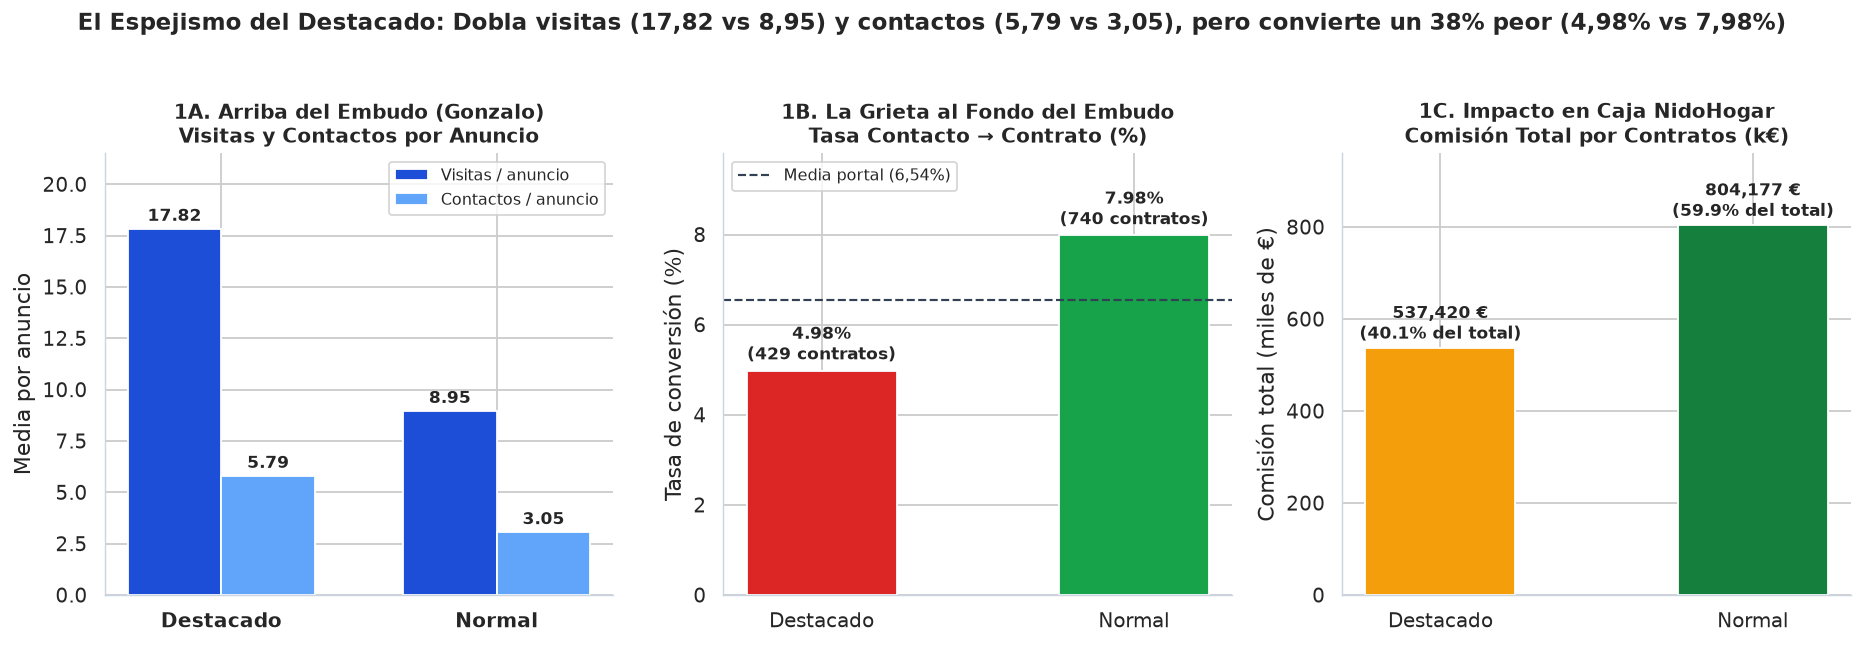

Guardado: reports/01_embudo_destacado_vs_normal.png


In [2]:
# --- GRÁFICO 1: 01_embudo_destacado_vs_normal.png ---
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.8))

etiquetas = ['Destacado', 'Normal']
x = np.arange(len(etiquetas))
w = 0.34

# Panel 1A: Visitas y Contactos por anuncio
b_vis = axes[0].bar(x - w/2, df_tipo['visitas_por_anuncio'], width=w, label='Visitas / anuncio', color='#1d4ed8')
b_con = axes[0].bar(x + w/2, df_tipo['contactos_por_anuncio'], width=w, label='Contactos / anuncio', color='#60a5fa')
axes[0].set_title('1A. Arriba del Embudo (Gonzalo)\nVisitas y Contactos por Anuncio', fontsize=11, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(etiquetas, fontweight='bold')
axes[0].set_ylabel('Media por anuncio')
axes[0].set_ylim(0, 21.5)
axes[0].legend(loc='upper right', frameon=True, fontsize=9)
for b in b_vis:
    axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + 0.4, f"{b.get_height():.2f}", ha='center', fontweight='bold', fontsize=9.5)
for b in b_con:
    axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + 0.4, f"{b.get_height():.2f}", ha='center', fontweight='bold', fontsize=9.5)

# Panel 1B: Tasa de conversión Contacto -> Contrato (%)
colores_conv = ['#dc2626', '#16a34a']
b_tasa = axes[1].bar(etiquetas, df_tipo['tasa_contacto_contrato_pct'], color=colores_conv, width=0.48)
axes[1].axhline(6.54, color='#334155', linestyle='--', linewidth=1.2, label='Media portal (6,54%)')
axes[1].set_title('1B. La Grieta al Fondo del Embudo\nTasa Contacto → Contrato (%)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Tasa de conversión (%)')
axes[1].set_ylim(0, 9.8)
axes[1].legend(loc='upper left', frameon=True, fontsize=9)
for b, r in zip(b_tasa, df_tipo.itertuples()):
    axes[1].text(b.get_x() + b.get_width()/2, b.get_height() + 0.25, f"{r.tasa_contacto_contrato_pct:.2f}%\n({int(r.contratos_totales)} contratos)", ha='center', fontweight='bold', fontsize=9.5)

# Panel 1C: Comisión Total (€ miles)
comisiones_k = df_tipo['comision_total_eur'] / 1000.0
b_com = axes[2].bar(etiquetas, comisiones_k, color=['#f59e0b', '#15803d'], width=0.48)
axes[2].set_title('1C. Impacto en Caja NidoHogar\nComisión Total por Contratos (k€)', fontsize=11, fontweight='bold')
axes[2].set_ylabel('Comisión total (miles de €)')
axes[2].set_ylim(0, 960)
for b, r in zip(b_com, df_tipo.itertuples()):
    axes[2].text(b.get_x() + b.get_width()/2, b.get_height() + 20, f"{r.comision_total_eur:,.0f} €\n({r.cuota_comision_pct:.1f}% del total)", ha='center', fontweight='bold', fontsize=9.5)

for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.suptitle('El Espejismo del Destacado: Dobla visitas (17,82 vs 8,95) y contactos (5,79 vs 3,05), pero convierte un 38% peor (4,98% vs 7,98%)', fontsize=12.5, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig(REPORTS_DIR / '01_embudo_destacado_vs_normal.png', dpi=300, bbox_inches='tight')
plt.show()
print("Guardado: reports/01_embudo_destacado_vs_normal.png")

### Análisis del Gráfico 1 (`01_embudo_destacado_vs_normal.png`)
* **Primero la razón, luego la grieta:** El panel `1A` concede a Gonzalo Prieto que el anuncio destacado casi duplica las visitas (`17,82` vs `8,95`) y los contactos (`5,79` vs `3,05`). Inmediatamente, el panel `1B` muestra cómo esa ventaja se invierte al medir la tasa de conversión a contrato (`4,98 %` en destacado vs `7,98 %` en normal), y el panel `1C` traduce esa caída a euros: los anuncios normales generan **`804.177 €` (`59,9 %`)** frente a **`537.420 €` (`40,1 %`)** de los destacados.

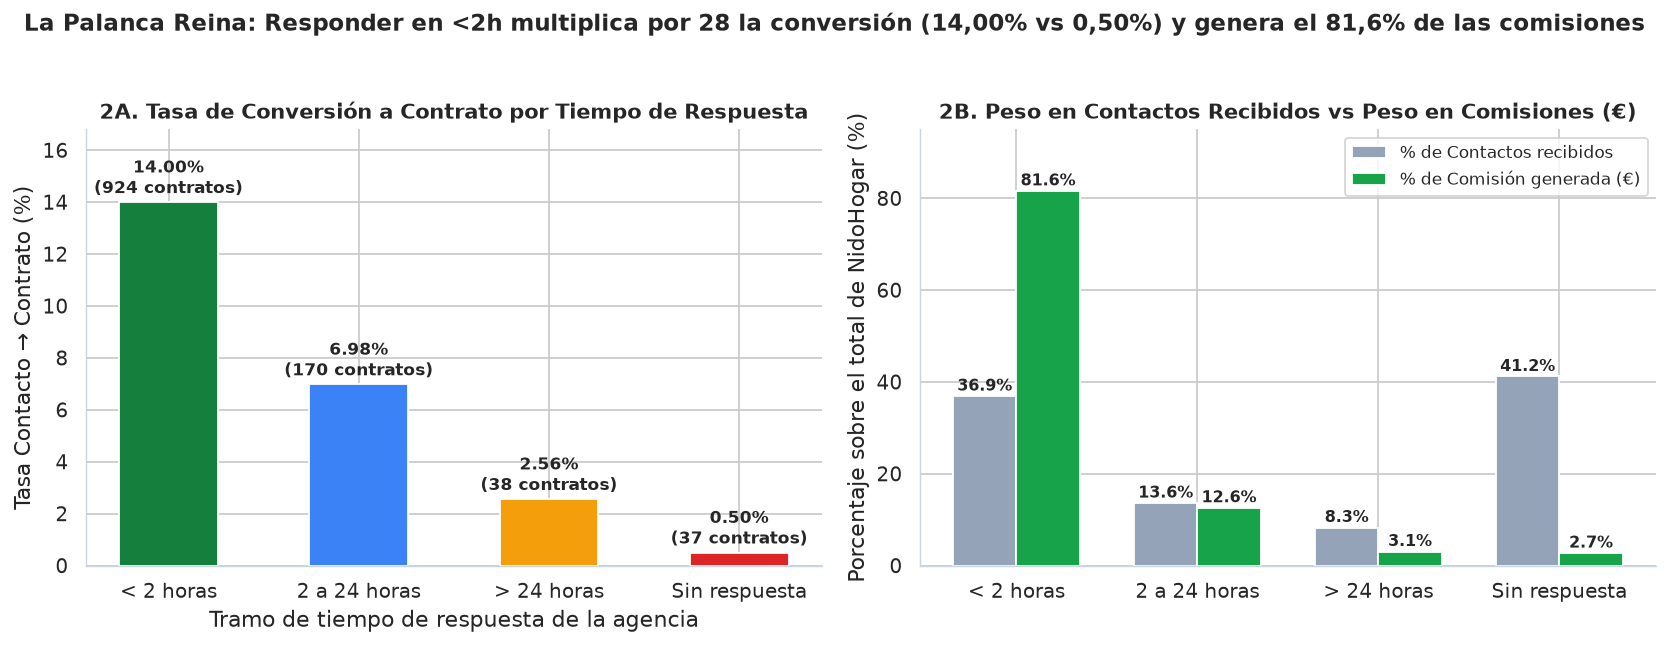

Guardado: reports/02_velocidad_respuesta_conversion.png


In [3]:
# --- GRÁFICO 2: 02_velocidad_respuesta_conversion.png ---
q_tramos = """
SELECT
    c.tramo_respuesta,
    COUNT(c.contacto_id) AS total_contactos,
    ROUND(COUNT(c.contacto_id) * 100.0 / (SELECT COUNT(*) FROM v_contactos), 2) AS cuota_contactos_pct,
    COUNT(ct.contrato_id) AS total_contratos,
    ROUND(COUNT(ct.contrato_id) * 100.0 / (SELECT COUNT(*) FROM v_contratos), 2) AS cuota_contratos_pct,
    ROUND(COUNT(ct.contrato_id) * 100.0 / COUNT(c.contacto_id), 2) AS tasa_conversion_pct,
    ROUND(SUM(COALESCE(ct.comision, 0)), 2) AS comision_total_eur,
    ROUND(SUM(COALESCE(ct.comision, 0)) * 100.0 / (SELECT SUM(comision) FROM v_contratos), 2) AS cuota_comision_pct
FROM v_contactos c
LEFT JOIN v_contratos ct USING (contacto_id)
GROUP BY c.tramo_respuesta
ORDER BY CASE c.tramo_respuesta
    WHEN '<2h' THEN 1
    WHEN '2-24h' THEN 2
    WHEN '>24h' THEN 3
    ELSE 4 END;
"""
df_tramos = con.execute(q_tramos).df()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
colores_tramos = ['#15803d', '#3b82f6', '#f59e0b', '#dc2626']
etiquetas_tramos = ['< 2 horas', '2 a 24 horas', '> 24 horas', 'Sin respuesta']

b1 = axes[0].bar(etiquetas_tramos, df_tramos['tasa_conversion_pct'], color=colores_tramos, width=0.52)
axes[0].set_title('2A. Tasa de Conversión a Contrato por Tiempo de Respuesta', fontsize=11.5, fontweight='bold')
axes[0].set_ylabel('Tasa Contacto → Contrato (%)')
axes[0].set_xlabel('Tramo de tiempo de respuesta de la agencia')
axes[0].set_ylim(0, 16.8)
for bar, r in zip(b1, df_tramos.itertuples()):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.35, f"{r.tasa_conversion_pct:.2f}%\n({int(r.total_contratos)} contratos)", ha='center', fontweight='bold', fontsize=9.5)

x_t = np.arange(len(etiquetas_tramos))
w_t = 0.35
b2_leads = axes[1].bar(x_t - w_t/2, df_tramos['cuota_contactos_pct'], width=w_t, label='% de Contactos recibidos', color='#94a3b8')
b2_com = axes[1].bar(x_t + w_t/2, df_tramos['cuota_comision_pct'], width=w_t, label='% de Comisión generada (€)', color='#16a34a')
axes[1].set_title('2B. Peso en Contactos Recibidos vs Peso en Comisiones (€)', fontsize=11.5, fontweight='bold')
axes[1].set_xticks(x_t)
axes[1].set_xticklabels(etiquetas_tramos)
axes[1].set_ylabel('Porcentaje sobre el total de NidoHogar (%)')
axes[1].set_ylim(0, 95)
axes[1].legend(loc='upper right', frameon=True, fontsize=9.5)
for b in b2_leads:
    axes[1].text(b.get_x() + b.get_width()/2, b.get_height() + 1.2, f"{b.get_height():.1f}%", ha='center', fontweight='bold', fontsize=9)
for b in b2_com:
    axes[1].text(b.get_x() + b.get_width()/2, b.get_height() + 1.2, f"{b.get_height():.1f}%", ha='center', fontweight='bold', fontsize=9)

for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.suptitle('La Palanca Reina: Responder en <2h multiplica por 28 la conversión (14,00% vs 0,50%) y genera el 81,6% de las comisiones', fontsize=12.5, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig(REPORTS_DIR / '02_velocidad_respuesta_conversion.png', dpi=300, bbox_inches='tight')
plt.savefig('grafico_1_tiempo_respuesta.png', dpi=300, bbox_inches='tight')
plt.show()
print("Guardado: reports/02_velocidad_respuesta_conversion.png")

### Análisis del Gráfico 2 (`02_velocidad_respuesta_conversion.png`)
* **La palanca que decide el negocio:** En `2A`, la tasa de conversión pasa del **`14,00 %`** cuando se responde en `<2h` al **`6,98 %`** en `2-24h`, **`2,56 %`** en `>24h` y **`0,50 %`** cuando no se responde (**$\times 28$** de diferencia entre los extremos).
* En `2B` se observa el coste directo del abandono: el **`41,19 %` de todos los contactos del portal (`7.364` leads) no recibe respuesta jamás** y aporta apenas el `2,7 %` de las comisiones, mientras que el **`36,91 %` atendido en `<2h`** sostiene el **`81,62 %` de la facturación por comisiones (`1.095.061 €`)**.

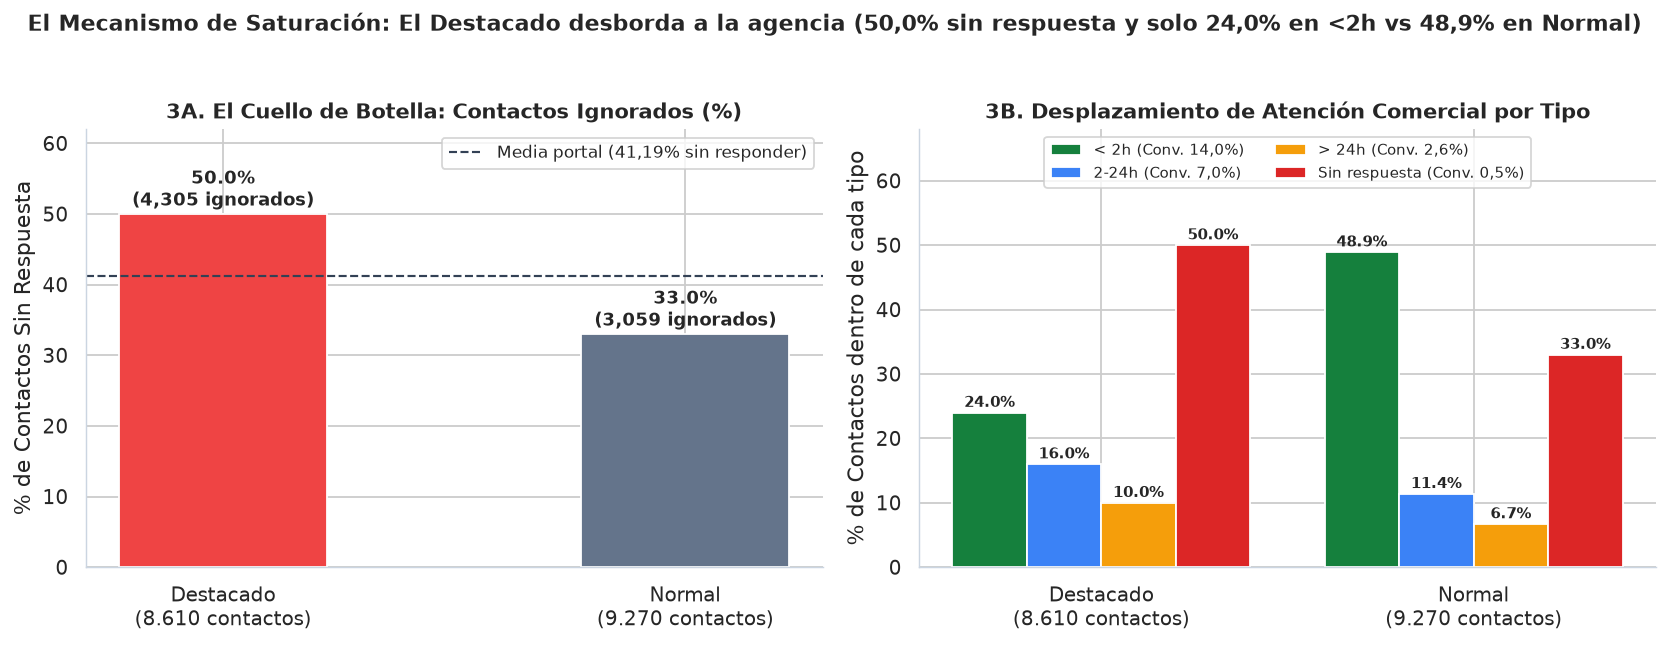

Guardado: reports/03_saturacion_agencias_destacado.png


In [4]:
# --- GRÁFICO 3: 03_saturacion_agencias_destacado.png ---
q_mix_tramos = """
SELECT
    a.tipo_anuncio,
    COUNT(c.contacto_id) AS total_contactos,
    SUM(CASE WHEN NOT c.respondido THEN 1 ELSE 0 END) AS sin_resp,
    ROUND(SUM(CASE WHEN NOT c.respondido THEN 1.0 ELSE 0 END) * 100.0 / COUNT(c.contacto_id), 2) AS pct_sin_responder,
    ROUND(SUM(CASE WHEN c.tramo_respuesta = '<2h' THEN 1.0 ELSE 0 END) * 100.0 / COUNT(c.contacto_id), 2) AS pct_lt2h,
    ROUND(SUM(CASE WHEN c.tramo_respuesta = '2-24h' THEN 1.0 ELSE 0 END) * 100.0 / COUNT(c.contacto_id), 2) AS pct_2_24h,
    ROUND(SUM(CASE WHEN c.tramo_respuesta = '>24h' THEN 1.0 ELSE 0 END) * 100.0 / COUNT(c.contacto_id), 2) AS pct_gt24h
FROM v_contactos c
JOIN v_anuncios a USING (anuncio_id)
GROUP BY a.tipo_anuncio
ORDER BY pct_sin_responder DESC;
"""
df_mix = con.execute(q_mix_tramos).df()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
tipos_label = ['Destacado\n(8.610 contactos)', 'Normal\n(9.270 contactos)']

# Panel 3A: % Contactos Sin Responder (50% vs 33%)
b_sat = axes[0].bar(tipos_label, df_mix['pct_sin_responder'], color=['#ef4444', '#64748b'], width=0.45)
axes[0].axhline(41.19, color='#334155', linestyle='--', linewidth=1.2, label='Media portal (41,19% sin responder)')
axes[0].set_title('3A. El Cuello de Botella: Contactos Ignorados (%)', fontsize=11.5, fontweight='bold')
axes[0].set_ylabel('% de Contactos Sin Respuesta')
axes[0].set_ylim(0, 62)
axes[0].legend(loc='upper right', frameon=True, fontsize=9.5)
for bar, r in zip(b_sat, df_mix.itertuples()):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.2, f"{r.pct_sin_responder:.1f}%\n({int(r.sin_resp):,} ignorados)", ha='center', fontweight='bold', fontsize=10)

# Panel 3B: Reparto completo por tramo de respuesta (<2h vs 2-24h vs >24h vs sin_respuesta)
x_m = np.arange(len(tipos_label))
w_m = 0.2
b_m1 = axes[1].bar(x_m - 1.5*w_m, df_mix['pct_lt2h'], width=w_m, label='< 2h (Conv. 14,0%)', color='#15803d')
b_m2 = axes[1].bar(x_m - 0.5*w_m, df_mix['pct_2_24h'], width=w_m, label='2-24h (Conv. 7,0%)', color='#3b82f6')
b_m3 = axes[1].bar(x_m + 0.5*w_m, df_mix['pct_gt24h'], width=w_m, label='> 24h (Conv. 2,6%)', color='#f59e0b')
b_m4 = axes[1].bar(x_m + 1.5*w_m, df_mix['pct_sin_responder'], width=w_m, label='Sin respuesta (Conv. 0,5%)', color='#dc2626')

axes[1].set_title('3B. Desplazamiento de Atención Comercial por Tipo', fontsize=11.5, fontweight='bold')
axes[1].set_xticks(x_m)
axes[1].set_xticklabels(tipos_label)
axes[1].set_ylabel('% de Contactos dentro de cada tipo')
axes[1].set_ylim(0, 68)
axes[1].legend(loc='upper center', ncol=2, frameon=True, fontsize=8.5)

for grp in [b_m1, b_m2, b_m3, b_m4]:
    for bar in grp:
        axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.9, f"{bar.get_height():.1f}%", ha='center', fontweight='bold', fontsize=8.5)

for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.suptitle('El Mecanismo de Saturación: El Destacado desborda a la agencia (50,0% sin respuesta y solo 24,0% en <2h vs 48,9% en Normal)', fontsize=12, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig(REPORTS_DIR / '03_saturacion_agencias_destacado.png', dpi=300, bbox_inches='tight')
plt.savefig('grafico_2_saturacion_destacado.png', dpi=300, bbox_inches='tight')
plt.show()
print("Guardado: reports/03_saturacion_agencias_destacado.png")

### Análisis del Gráfico 3 (`03_saturacion_agencias_destacado.png`)
* **El mecanismo de la saturación al descubierto:** El panel `3A` muestra que en los anuncios destacados se ignora exactamente el **`50,0 %` de los mensajes (`4.305` leads perdidos)** frente al **`33,0 %` (`3.059` leads)** en los normales.
* El panel `3B` muestra hacia dónde se desplaza ese volumen: mientras que en un anuncio `normal` casi 1 de cada 2 leads (**`48,9 %`**) es contestado en menos de 2 horas, en el `destacado` esa proporción cae a la mitad (**`24,0 %`**).

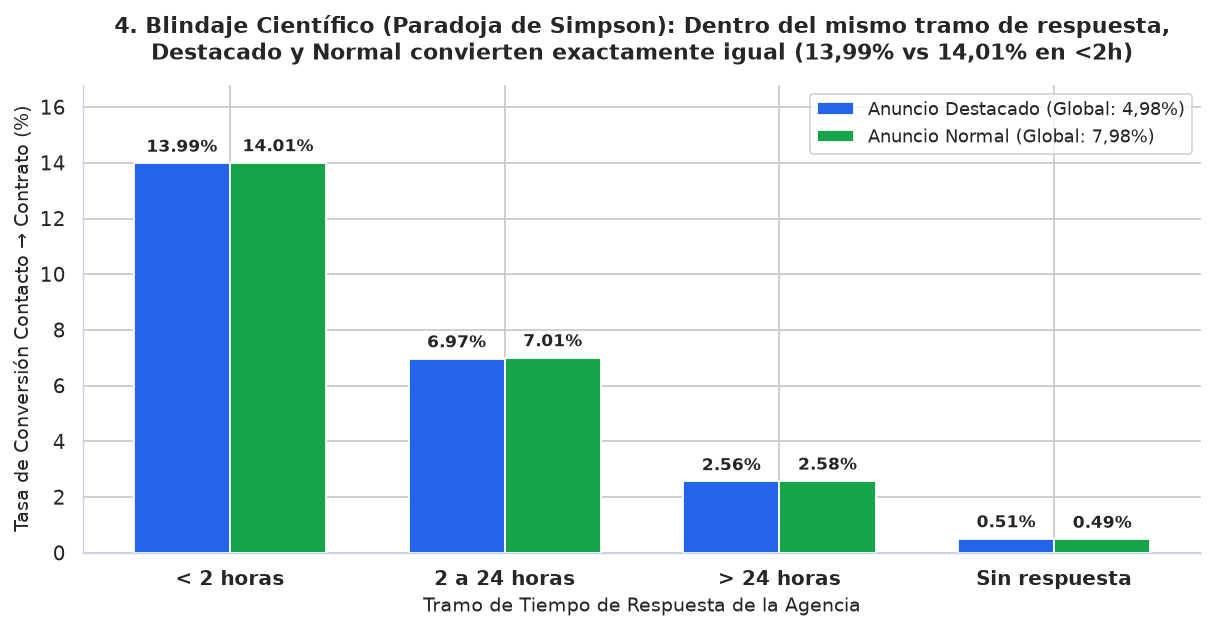

Guardado: reports/04_control_confusion_tramos_respuesta.png


In [5]:
# --- GRÁFICO 4: 04_control_confusion_tramos_respuesta.png ---
q_control = """
SELECT
    c.tramo_respuesta,
    ROUND(SUM(CASE WHEN a.tipo_anuncio = 'destacado' AND ct.contrato_id IS NOT NULL THEN 1.0 ELSE 0 END) * 100.0 /
          NULLIF(SUM(CASE WHEN a.tipo_anuncio = 'destacado' THEN 1.0 ELSE 0 END), 0), 2) AS Destacado,
    ROUND(SUM(CASE WHEN a.tipo_anuncio = 'normal' AND ct.contrato_id IS NOT NULL THEN 1.0 ELSE 0 END) * 100.0 /
          NULLIF(SUM(CASE WHEN a.tipo_anuncio = 'normal' THEN 1.0 ELSE 0 END), 0), 2) AS Normal
FROM v_contactos c
JOIN v_anuncios a USING (anuncio_id)
LEFT JOIN v_contratos ct USING (contacto_id)
GROUP BY c.tramo_respuesta
ORDER BY CASE c.tramo_respuesta
    WHEN '<2h' THEN 1
    WHEN '2-24h' THEN 2
    WHEN '>24h' THEN 3
    ELSE 4 END;
"""
df_ctrl = con.execute(q_control).df()

fig, ax = plt.subplots(figsize=(9.5, 5.0))
x_c = np.arange(len(df_ctrl['tramo_respuesta']))
w_c = 0.35

rects1 = ax.bar(x_c - w_c/2, df_ctrl['Destacado'], w_c, label='Anuncio Destacado (Global: 4,98%)', color='#2563eb')
rects2 = ax.bar(x_c + w_c/2, df_ctrl['Normal'], w_c, label='Anuncio Normal (Global: 7,98%)', color='#16a34a')

ax.set_title('4. Blindaje Científico (Paradoja de Simpson): Dentro del mismo tramo de respuesta,\nDestacado y Normal convierten exactamente igual (13,99% vs 14,01% en <2h)', fontsize=12, fontweight='bold', pad=14)
ax.set_xticks(x_c)
ax.set_xticklabels(['< 2 horas', '2 a 24 horas', '> 24 horas', 'Sin respuesta'], fontweight='bold')
ax.set_ylabel('Tasa de Conversión Contacto → Contrato (%)', fontsize=10.5)
ax.set_xlabel('Tramo de Tiempo de Respuesta de la Agencia', fontsize=10.5)
ax.legend(frameon=True, fontsize=10, loc='upper right')
ax.set_ylim(0, 16.8)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

for r in [rects1, rects2]:
    for bar in r:
        y = bar.get_height()
        ax.annotate(f"{y:.2f}%",
                    xy=(bar.get_x() + bar.get_width() / 2, y),
                    xytext=(0, 4), textcoords="offset points",
                    ha='center', va='bottom', fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.savefig(REPORTS_DIR / '04_control_confusion_tramos_respuesta.png', dpi=300, bbox_inches='tight')
plt.savefig('grafico_3_control_tramos.png', dpi=300, bbox_inches='tight')
plt.show()
print("Guardado: reports/04_control_confusion_tramos_respuesta.png")

### Análisis del Gráfico 4 (`04_control_confusion_tramos_respuesta.png`) y Conclusión Ejecutiva

* **El blindaje definitivo frente a cualquier objeción:** Cuando comparamos anuncios `destacados` y `normales` a igual velocidad de atención comercial, las barras quedan empatadas al centésimo en los cuatro tramos: **`13,99 %` vs `14,01 %` en `<2h`**, **`6,97 %` vs `7,01 %` en `2-24h`**, **`2,56 %` vs `2,58 %` en `>24h`** y **`0,51 %` vs `0,49 %` en `sin_respuesta`**.
* **Decisión para Álvaro Nadal (CEO):**
  1. **NO lanzar «Destacado Premium» como palanca de crecimiento de contratos:** Vender aún más visibilidad a agencias que ya ignoran el **`50,0 %`** de los leads destacados solo inflará la bolsa de mensajes sin respuesta sin mover la aguja de contratos ni comisiones.
  2. **Condicionar el algoritmo de posicionamiento al SLA de respuesta (`<2h`):** Incorporar la tasa de respuesta en `<2h` como factor multiplicador del ranking en NidoHogar, premiando a las agencias que atienden rápido.
  3. **Activar alertas push y límite de saturación comercial:** Desplegar notificaciones en tiempo real e impedir la compra de nuevos destacados a agencias que superen el **`40 %` de contactos sin responder** (como las 10 agencias críticas identificadas en el Día 4), liberando un potencial de **`+258` contratos y `+337.358 €` anuales en comisiones**.